In [11]:
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Activation, Conv2D, MaxPooling2D
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [12]:
# Load and explore
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

print("Dimensions of TRAINING data:", X_train.shape)
print("No. of class labels in TRAINING data:", len(y_train))
print("First 10 class labels of training data:", y_train[0:10])
print("Dimensions of class labels of the TESTING data:", y_test.shape)
print("Len of class labels in TESTING data:", len(y_test))

Dimensions of TRAINING data: (60000, 28, 28)
No. of class labels in TRAINING data: 60000
First 10 class labels of training data: [9 0 0 3 0 2 7 2 5 5]
Dimensions of class labels of the TESTING data: (10000,)
Len of class labels in TESTING data: 10000


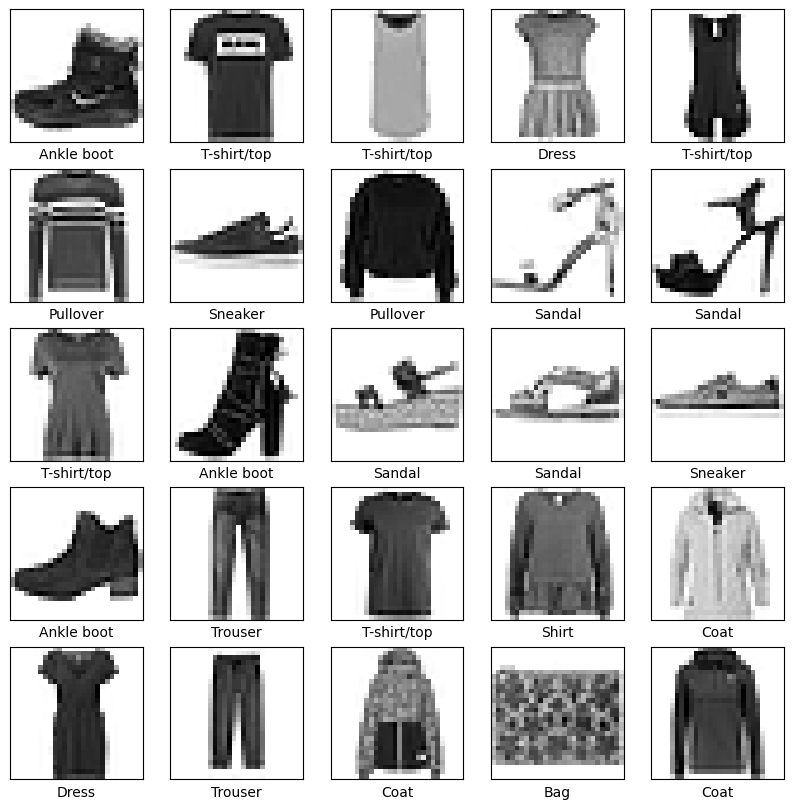

In [13]:
# Scale and visualize
X_train = X_train.astype('float32') / 255
X_test = X_test.astype('float32') / 255

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(X_train[i], cmap=plt.cm.binary)
    plt.xlabel(class_names[y_train[i]])
plt.show()

In [14]:
# Parameters and reshape
batch_size = 128
num_classes = 10
epochs = 12

img_rows, img_cols = 28, 28
X_train = X_train.reshape(X_train.shape[0], img_rows, img_cols, 1)
X_test = X_test.reshape(X_test.shape[0], img_rows, img_cols, 1)
input_shape = (img_rows, img_cols, 1)

In [15]:
# Build the model
model = Sequential()
model.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=input_shape))
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(num_classes, activation='softmax'))

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 22, 22, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 11, 11, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 11, 11, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 15488)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,982,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,076,554 (7.92 MB)

 Trainable params: 2,076,554 (7.92 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Compile and train
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(X_train, y_train, batch_size=batch_size, epochs=epochs,
                    verbose=1, validation_data=(X_test, y_test))

Epoch 1/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.8187 - loss: 0.5129 - val_accuracy: 0.8857 - val_loss: 0.3134
Epoch 2/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.8853 - loss: 0.3204 - val_accuracy: 0.9051 - val_loss: 0.2585
Epoch 3/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.9031 - loss: 0.2680 - val_accuracy: 0.9110 - val_loss: 0.2395
Epoch 4/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.9125 - loss: 0.2412 - val_accuracy: 0.9145 - val_loss: 0.2312
Epoch 5/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.9215 - loss: 0.2136 - val_accuracy: 0.9146 - val_loss: 0.2284
Epoch 6/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.9293 - loss: 0.1939 - val_accuracy: 0.9230 - val_loss: 0.2149
Epoch 7/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.9334 - loss: 0.1783 - val_accuracy: 0.9231 - val_loss: 0.2131
Epoch 8/12
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.9393 - loss: 0.1612 - val_acc

In [17]:
# Evaluate
score = model.evaluate(X_test, y_test, verbose=0)
print('Test Loss:', score[0])
print('Test Accuracy:', score[1])

Test Loss: 0.23979021608829498
Test Accuracy: 0.9280999898910522


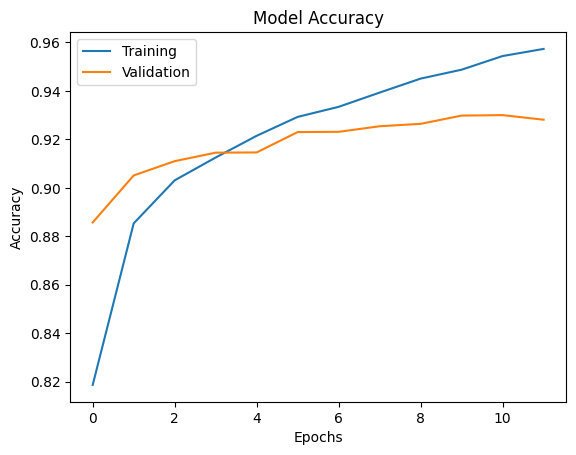

In [18]:
# Accuracy graph
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['Training', 'Validation'])
plt.show()

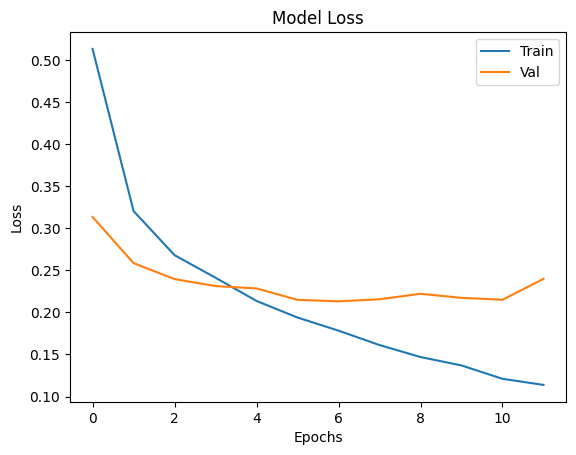

In [19]:
# Loss graph (fixed title)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epochs')
plt.legend(['Train', 'Val'], loc='upper right')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 411ms/step
Ankle boot


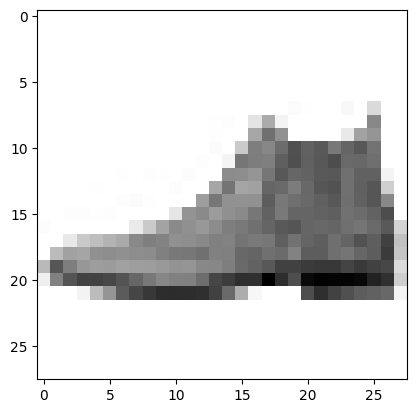

In [20]:
# Predict one image
predictions = model.predict(X_test[:1])
label = class_names[np.argmax(predictions)]

print(label)
plt.imshow(X_test[0].squeeze(), cmap=plt.cm.binary)
plt.show()